# 01 — Setup: dataset, coordinates, probes, corruption


**Setup.** Nektar cylinder wake (Raissi PINN data), 200 snapshots × 5000 grid points (100 × 50, x∈[1,8], y∈[−2,2]).
Target: both velocity components, state = [u; v] (10 000 values). N = 8 probes, each reading u and v at one grid point,
placed by block-QR pivoting over grid points on the rank-16 POD basis of the training data. Lags = 10, interleaved
80/10/10 window split, seeds {0, 1, 2} (seed changes split, probe locations, POD basis and init). GRU for all recurrent models.

**Corruption (identical for all methods).** Gaussian noise σ = 0.05 × per-channel training std, added in unscaled
units (fresh per batch in training; fixed seeded realisation at test). Dropout: each probe fails with probability p for
the whole lag window (both channels), at least one probe survives. Training p = 0.3 for "-dropout" and masked models.
Test: p = 0 and p = 0.3, 10 fixed draws per test window, shared across methods (and gappy POD).
Zero-fill methods see 0 in the min-max scaled input space (= training minimum of that probe, not "no signal").
Masked methods (SenseiverSDN, RobustSHREDv1/v2) exclude failed probes from attention (key padding mask + learned null
token); gappy POD solves least squares with the available rows, rank r' = min(16, 2·available), clipped to the
training range. Early stopping uses a validation set corrupted like the method's training data.

In [1]:
RUN_TRAINING = False   # True: train runs that are not cached yet (cached runs are skipped)
QUICK = False          # True: 1 seed, 20 epochs, separate cache dir (smoke test)

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from get_shredded import meeting_plots as mp
from get_shredded.meeting_runner import (
    LATENT_METHODS, load_arrays, load_config, load_results, load_seed_info, prepare_seed, run_all,
)

TIER_A = ["SHRED-noise", "SHRED-dropout", "SDN-noise", "SDN-dropout",
          "SenseiverSDN", "RobustSHREDv1", "RobustSHREDv2", "GappyPOD"]
TIER_B = ["SHRED-dropout+mask"]
METHODS = TIER_A + TIER_B
OVERRIDES = ["meeting.methods=[" + ",".join(METHODS) + "]"]
if QUICK:
    OVERRIDES += ["meeting.seeds=[0]", "train.epochs=20", "outputs.root=outputs/meeting_2026-10-14_quick"]
cfg = load_config(OVERRIDES)
ROOT = cfg.outputs.root
if RUN_TRAINING:
    run_all(cfg)
results = load_results(ROOT)
print(f"{len(results)} completed runs in {ROOT}")

27 completed runs in outputs/meeting_2026-10-14


## Dataset and coordinate check

In [2]:
from scipy.io import loadmat
from get_shredded.data import nektar_point_coordinates
from get_shredded.meeting_runner import _abs

sd = prepare_seed(cfg, 0)
print("raw full state (N_time, N_state):", sd.load_X.shape, "| grid points:", sd.n_points, "| channels:", sd.channels)
raw = loadmat(str(_abs(cfg.data.nektar_file)))
X_star, U_star = raw["X_star"], raw["U_star"]
coords = nektar_point_coordinates(_abs(cfg.data.nektar_file))
# map every state index back to its row in X_star and compare u, v at t = 0
row = {tuple(np.round(p, 9)): i for i, p in enumerate(X_star)}
rows = np.array([row[tuple(np.round(p, 9))] for p in coords])
du = np.abs(sd.load_X[0, :sd.n_points] - U_star[rows, 0, 0]).max()
dv = np.abs(sd.load_X[0, sd.n_points:] - U_star[rows, 1, 0]).max()
print(f"every state index maps to a unique X_star point: {len(set(rows)) == sd.n_points}")
print(f"max |u_state - U_star| = {du:.2e}, max |v_state - V_star| = {dv:.2e}")

raw full state (N_time, N_state): (200, 10000) | grid points: 5000 | channels: 2


every state index maps to a unique X_star point: True
max |u_state - U_star| = 5.96e-08, max |v_state - V_star| = 2.98e-08


**Takeaway:** Raw state is (200, 10000) = [u; v] on 5000 grid points; every state index maps to a unique X_star point and reproduces U_star to float32 rounding (≤ 6e-8), so the positional-encoding coordinates are exact, not guessed.

## Probe locations (block-QR, fit on training data per seed)

seed 0: (3.33, 0.04), (3.55, 0.04), (2.77, 0.04), (3.05, 0.04), (3.83, 0.04), (4.11, 0.04), (4.46, -0.04), (4.82, -0.04)
seed 1: (3.26, 0.04), (3.05, 0.04), (3.55, 0.04), (3.83, 0.04), (2.77, 0.04), (4.11, 0.04), (4.39, -0.04), (4.75, -0.04)
seed 2: (3.19, -0.04), (3.40, -0.04), (2.91, -0.04), (3.69, -0.04), (3.97, -0.04), (2.63, -0.04), (4.32, -0.04), (4.68, 0.04)


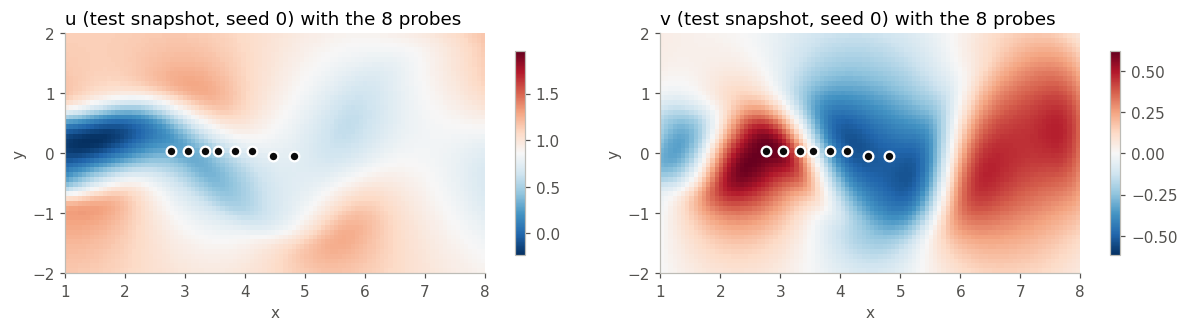

In [3]:
for s in cfg.meeting.seeds:
    info = load_seed_info(ROOT, int(s))
    pts = info["point_coordinates"][info["locations"]]
    print(f"seed {s}: " + ", ".join(f"({x:.2f}, {y:.2f})" for x, y in pts))
info = load_seed_info(ROOT, 0)
fig = mp.plot_sensor_layout(info, sd.truth[0], title="(test snapshot, seed 0) with the 8 probes")
mp.save(fig, ROOT, "01_probe_layout"); plt.show()

**Takeaway:** Block-QR places all 8 probes on the wake centreline (|y| ≈ 0.04, x ≈ 2.6–4.8) for all three seeds, i.e. a tightly clustered line where v is largest; neighbouring probes carry partly redundant information.

## Example probe signal: clean vs noisy vs dropped (scaled input space)

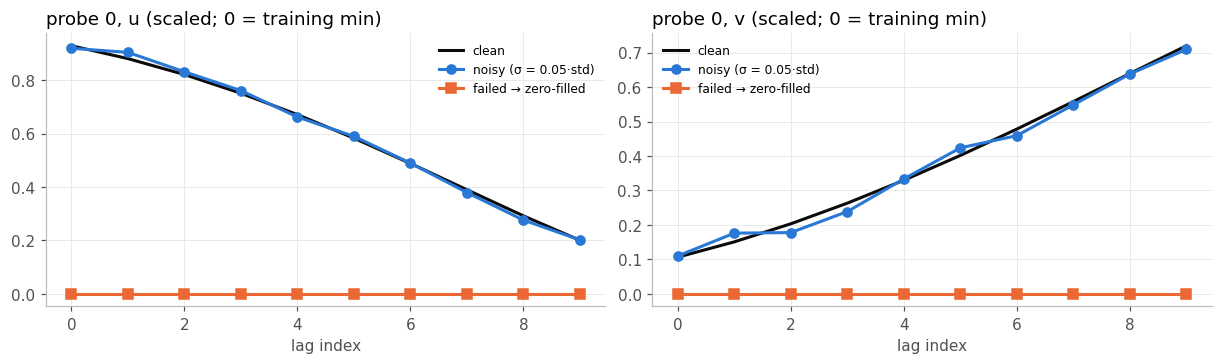

zero-fill corresponds to these unscaled values (training min per probe channel):
  u: 0.358, 0.404, 0.196, 0.284, 0.458, 0.502, 0.547, 0.584
  v: -0.583, -0.573, -0.609, -0.596, -0.558, -0.545, -0.527, -0.514
noise σ (unscaled): [0.0046 0.0046 0.0049 0.0048 0.0043 0.004  0.0038 0.0036 0.0233 0.0234
 0.0233 0.0231 0.023  0.0225 0.022  0.0213]


In [4]:
probe = 0
w = 0  # first test window
window_clean = sd.windows[sd.test_idx[w]]                       # (lags, 2N) scaled
noise_scaled = sd.test_noise[0, w] / sd.sensor_range
mask = sd.test_mask[0.3][0, w]
from get_shredded.corruption import corrupt_numpy
noisy = corrupt_numpy(window_clean[None], noise_scaled[None], None, sd.channels)[0]
dropped = corrupt_numpy(window_clean[None], noise_scaled[None], mask[None] | (np.arange(sd.num_sensors) == probe)[None], sd.channels)[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), constrained_layout=True)
for c, ax in enumerate(axes):
    col = c * sd.num_sensors + probe
    t = np.arange(sd.lags)
    ax.plot(t, window_clean[:, col], color="#0b0b0b", label="clean")
    ax.plot(t, noisy[:, col], color="#2a78d6", marker="o", label="noisy (σ = 0.05·std)")
    ax.plot(t, dropped[:, col], color="#eb6834", marker="s", label="failed → zero-filled")
    ax.set_title(f"probe {probe}, {'uv'[c]} (scaled; 0 = training min)", loc="left")
    ax.set_xlabel("lag index"); ax.legend(frameon=False, fontsize=8)
mp.save(fig, ROOT, "01_probe_signal"); plt.show()
lo, hi = sd.scaler.data_min_[sd.state_indices], sd.scaler.data_max_[sd.state_indices]
print("zero-fill corresponds to these unscaled values (training min per probe channel):")
for c in range(sd.channels):
    print(f"  {'uv'[c]}: " + ", ".join(f"{v:.3f}" for v in lo[c * sd.num_sensors:(c + 1) * sd.num_sensors]))
print("noise σ (unscaled):", np.round(sd.sigma, 4))

**Takeaway:** σ is ≈ 0.004–0.005 for u and ≈ 0.022 for v at these probes. Zero-fill corresponds to u ≈ 0.20–0.58 and v ≈ −0.51…−0.61 in physical units — plausible-looking readings, not 'no signal'.